# Quadratic and Cubic B-Splines Demo
This notebook demonstrates quadratic nodal functions and B-splines using Julia and Plots.

In [1]:
using Plots, LaTeXStrings

## Define Quadratic shape functions
We define three quadratic shape functions.

In [2]:
ϕ1(y) = 1 / 8 * (1 - 2 * y + y^2)
ϕ2(y) = 1 / 4 * (3 - y^2)
ϕ3(y) = 1 / 8 * (1 + 2*y + y^2)

ϕ3 (generic function with 1 method)

## Plot Quadratic shape Functions
Visualize the three shape basis over the interval y ∈ [-1, 1] and beyond.

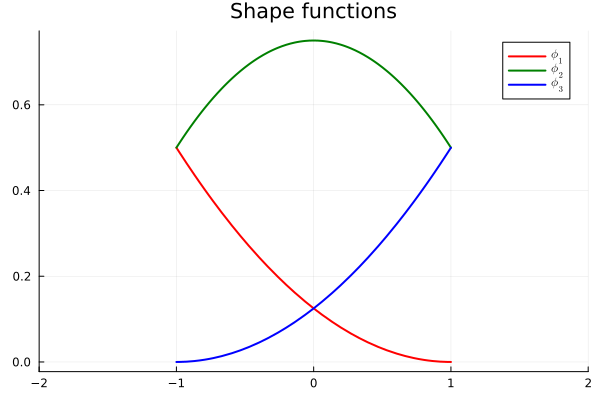

In [3]:
p1 = plot(title = "Shape functions")
color = :red
plot!(p1, ϕ1, xlims = (-1, 1), color = color, linewidth = 2, label = L"\phi_1")

color = :green
plot!(p1, ϕ2, xlims = (-1, 1), color = color, linewidth = 2, label = L"\phi_2")

color = :blue
plot!(p1, ϕ3, xlims = (-1, 1), color = color, linewidth = 2, label = L"\phi_3")

xlims!(p1, -2, 2)

## Plot Quadratic B-Spline
Visualize the quadratic B-spline using shifted shape functions.

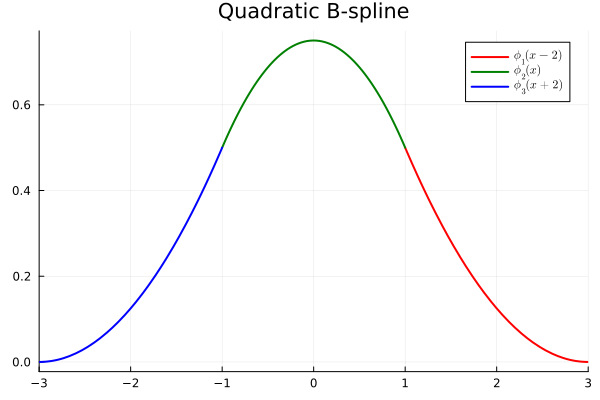

In [4]:
p2 = plot(title = "Quadratic B-spline")

color = :red
plot!(
    p2,
    x -> ϕ1(x - 2),
    xlims = (1, 3),
    color = color,
    linewidth = 2,
    label = L"\phi_1(x-2)",
)

color = :green
plot!(p2, ϕ2, xlims = (-1, 1), color = color, linewidth = 2, label = L"\phi_2(x)")

color = :blue
plot!(
    p2,
    x -> ϕ3(x + 2),
    xlims = (-3, -1),
    color = color,
    linewidth = 2,
    label = L"\phi_3(x+2)",
)
xlims!(p2, -3, 3)

In [5]:
plot(p1, p2, plot_width = 1000)
savefig("Bsplines_quadratic_shape.pdf")

"/private/tmp/uam-mnu-review/run/Bsplines/Bsplines_quadratic_shape.pdf"

## Plot B-Splines Using BSplines.jl
We plot degrees 2 and 3 (orders 3 and 4). `BSplineBasis(p + 1, x)` takes the order and a vector of breakpoints. The package forms a clamped knot vector by repeating each endpoint `p + 1` times. For degree 2 and the breakpoints below, the full knot vector is `[-0.3, -0.3, -0.3, 1.1, 1.4, 2.0, 2.0, 2.0]`.

In Cox–de Boor recursion, a term whose denominator vanishes is interpreted as zero. At the right endpoint use the limit from the left.

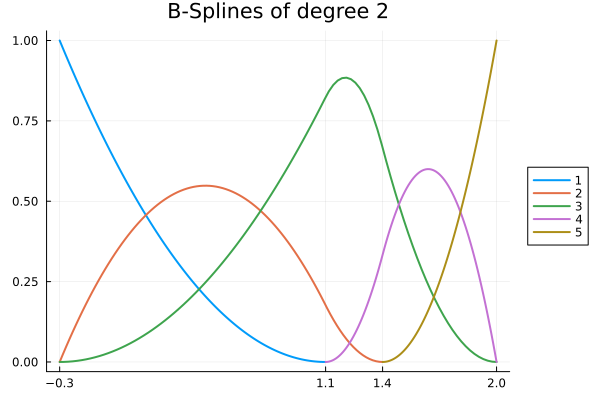

In [6]:
using BSplines
x = [-0.3, 1.1, 1.4, 2.0]
p = 2
basis = BSplineBasis(p + 1, x)
plot(legend = :outerright, title = "B-Splines of degree $p")
plot!(basis, linewidth = 2)
xticks!(x)

In [7]:
savefig("Bsplines_quadratic_basis.pdf")

"/private/tmp/uam-mnu-review/run/Bsplines/Bsplines_quadratic_basis.pdf"

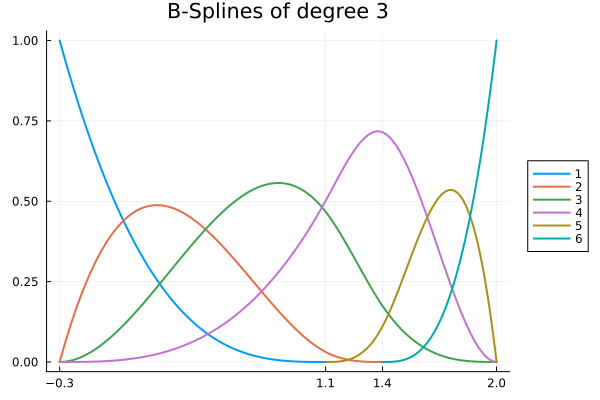

In [8]:
x = [-0.3, 1.1, 1.4, 2.0]
p = 3
basis = BSplineBasis(p + 1, x)
plot(legend = :outerright, title = "B-Splines of degree $p")
plot!(basis, linewidth = 2)
xticks!(x)

In [9]:
savefig("Bsplines_cubic_basis.pdf")

"/private/tmp/uam-mnu-review/run/Bsplines/Bsplines_cubic_basis.pdf"